# Pipeline de difusión latente

Genera flores haciendo **difusión en el espacio latente** de un autoencoder:

imagen -> [encode] -> latente -> difusión (forward + muestreo eta) -> latente -> [decode] -> imagen

**Alcance actual.** La difusión se implementa a mano (forward, muestreo con la perilla eta, oráculo entrenado desde cero). El autoencoder, por ahora, es uno preentrenado y congelado (KL-f8).

## 0. Instalacion, entorno y Drive

In [ ]:
#!pip -q install -U diffusers transformers accelerate safetensors huggingface_hub

import torch
from google.colab import drive
drive.mount('/content/drive')

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 122.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 107.3 MB/s eta 0:00:00
Mounted at /content/drive
device: cuda


## 1. Configuración

In [ ]:
CONFIG = {
    'data_dir': '/content/drive/MyDrive/flower-diffusion/flowers',   # flores
    'work_dir': '/content/drive/MyDrive/flower-diffusion/latente',
    'ae_name':  'stabilityai/sd-vae-ft-mse',   # autoencoder congelado (reemplazable)
    'ae_image_size': 256,

    'latent_ch': 4,
    'latent_size': 32,

    'base_channels': 128,
    'channel_mults': (1, 2, 4),
    'num_res_blocks': 2,
    'attn_resolutions': (16,),
    'time_emb_dim': 128,

    'T': 1000,
    'beta_start': 1e-4,
    'beta_end': 0.02,

    'epochs': 60,
    'batch_size': 64,
    'lr': 2e-4,
    'ema_decay': 0.999,
    'grad_clip': 1.0,
    'amp': True,
    'num_workers': 2,
    'seed': 0,
}

import os
os.makedirs(CONFIG['work_dir'], exist_ok=True)

## 2. Autoencoder congelado + encode / decode

El autoencoder comprime la imagen (256x256) a un latente (32x32x4) y la reconstruye. Lo usamos **congelado**: `requires_grad_(False)` deja fijos sus pesos, no se entrena. El `scaling_factor` normaliza el latente a varianza cercana a 1 (se aplica al codificar y se revierte al decodificar).

El smoke test reconstruye unas flores.

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

scaling_factor: 0.18215


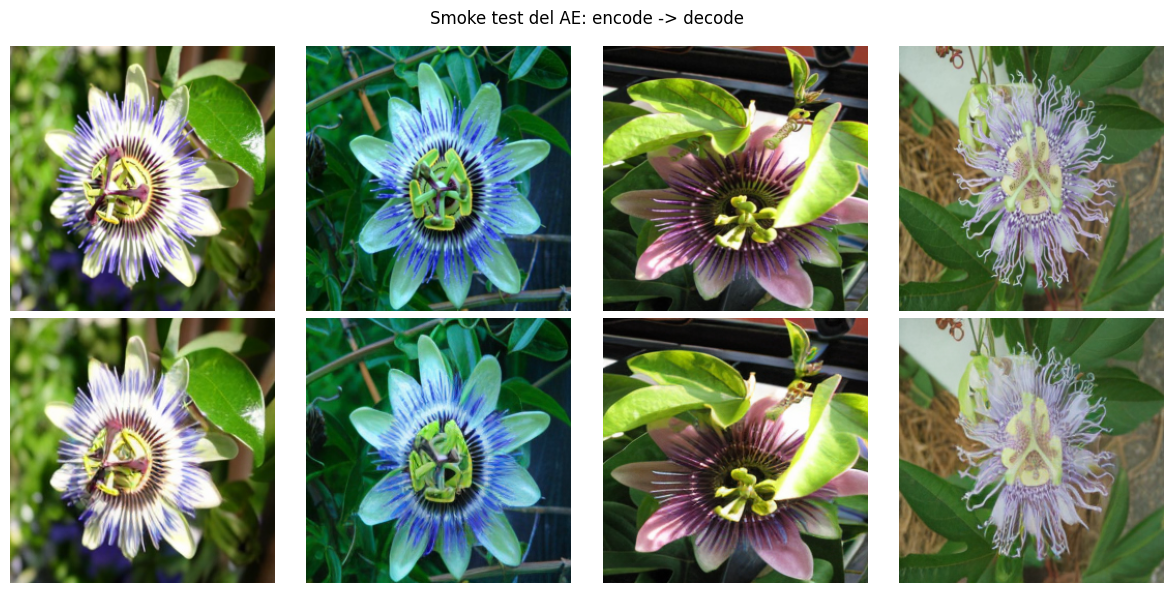

In [ ]:
# [IA] Carga del autoencoder preentrenado (sd-vae-ft-mse)
# y las funciones encode/decode, con apoyo de IA.

from diffusers import AutoencoderKL
from PIL import Image
import torchvision.transforms as T
import matplotlib.pyplot as plt

# cargar el autoencoder y congelarlo
vae = AutoencoderKL.from_pretrained(CONFIG['ae_name']).to(DEVICE).eval()
for p in vae.parameters():
    p.requires_grad_(False)
SCALE = vae.config.scaling_factor
print('scaling_factor:', SCALE)


@torch.no_grad()
def encode(x):
    # x: imagen (B, 3, 256, 256) en [-1, 1]  ->  latente (B, 4, 32, 32)
    latente = vae.encode(x).latent_dist.mean    # usamos la media (codificacion estable)
    return latente * SCALE


@torch.no_grad()
def decode(z):
    # z: latente (B, 4, 32, 32)  ->  imagen (B, 3, 256, 256) en [-1, 1]
    imagen = vae.decode(z / SCALE).sample
    return imagen.clamp(-1, 1)


# --- smoke test: reconstruir 4 flores ---
transform = T.Compose([
    T.Resize((CONFIG['ae_image_size'], CONFIG['ae_image_size'])),
    T.ToTensor(),
    T.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

nombres = sorted(f for f in os.listdir(CONFIG['data_dir']) if f.lower().endswith(('.jpg', '.jpeg', '.png')))
nombres = nombres[:4]

originales = []
for nombre in nombres:
    img = Image.open(os.path.join(CONFIG['data_dir'], nombre)).convert('RGB')
    originales.append(transform(img))
originales = torch.stack(originales).to(DEVICE)

reconstruidas = decode(encode(originales))

fig, axes = plt.subplots(2, len(nombres), figsize=(3 * len(nombres), 6))
for i in range(len(nombres)):
    orig = (originales[i].cpu() + 1) / 2
    rec = (reconstruidas[i].cpu() + 1) / 2
    axes[0, i].imshow(orig.permute(1, 2, 0).numpy().clip(0, 1))
    axes[0, i].axis('off')
    axes[1, i].imshow(rec.permute(1, 2, 0).numpy().clip(0, 1))
    axes[1, i].axis('off')
axes[0, 0].set_ylabel('original', rotation=0, labelpad=35, va='center')
axes[1, 0].set_ylabel('recon AE', rotation=0, labelpad=35, va='center')
plt.suptitle('Smoke test del AE: encode -> decode')
plt.tight_layout()
plt.show()

## 3. Cache de latentes

Codificamos todas las flores una vez a 32x32x4 y guardamos el tensor. Así el entrenamiento no pasa por el autoencoder en cada epoca.

In [ ]:
# [IA] Caché de latentes: codificar las flores una vez
# y guardar/recargar el tensor, con apoyo de IA.

from torch.utils.data import Dataset, DataLoader, TensorDataset

LAT_CACHE = os.path.join(CONFIG['work_dir'], 'latents.pt')

if os.path.exists(LAT_CACHE):
    latents = torch.load(LAT_CACHE)
    print('Latentes cargados:', tuple(latents.shape))
else:
    class CarpetaImagenes(Dataset):
        def __init__(self, folder):
            self.folder = folder
            self.files = sorted(f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.jpeg', '.png')))
        def __len__(self):
            return len(self.files)
        def __getitem__(self, i):
            img = Image.open(os.path.join(self.folder, self.files[i])).convert('RGB')
            return transform(img)

    loader_imgs = DataLoader(CarpetaImagenes(CONFIG['data_dir']), batch_size=32,
                             num_workers=CONFIG['num_workers'])

    # codificamos por lotes y vamos acumulando
    trozos = []
    for batch_imgs in loader_imgs:
        batch_latentes = encode(batch_imgs.to(DEVICE)).cpu()
        trozos.append(batch_latentes)
    latents = torch.cat(trozos, dim=0)

    torch.save(latents, LAT_CACHE)
    print('Latentes codificados y guardados:', tuple(latents.shape))

lat_loader = DataLoader(TensorDataset(latents), batch_size=CONFIG['batch_size'],
                        shuffle=True, drop_last=True, num_workers=CONFIG['num_workers'])
print('Batches por epoca:', len(lat_loader))

Latentes cargados: (8189, 4, 32, 32)
Batches por epoca: 127


## 4. Clases del modelo (oráculo latente) y proceso de difusión

In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


class TimeEmbedding(nn.Module):
    # Convierte el numero de paso t en un vector, para que la red sepa
    # en que nivel de ruido esta trabajando.
    def __init__(self, time_emb_dim):
        super().__init__()
        self.linear1 = nn.Linear(time_emb_dim, time_emb_dim * 4)
        self.linear2 = nn.Linear(time_emb_dim * 4, time_emb_dim)
        self.act = nn.SiLU()

    def get_sinusoidal_embedding(self, t, dim):
        # Codificacion seno/coseno del paso t (misma idea que en los Transformers).
        half = dim // 2
        freq = math.log(10000) / (half - 1)
        freq = torch.exp(torch.arange(half, device=t.device) * -freq)
        angles = t.float().unsqueeze(1) * freq.unsqueeze(0)
        return torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)

    def forward(self, t, dim):
        emb = self.get_sinusoidal_embedding(t, dim)
        emb = self.act(self.linear1(emb))
        emb = self.linear2(emb)
        return emb


class ResBlock(nn.Module):
    # Bloque convolucional con conexion residual, que ademas recibe la
    # informacion del paso t.
    def __init__(self, in_ch, out_ch, time_emb_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_ch)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.act = nn.SiLU()
        self.time_proj = nn.Linear(time_emb_dim, out_ch)
        # Si cambian los canales, ajustamos el atajo residual con una conv 1x1.
        if in_ch != out_ch:
            self.residual = nn.Conv2d(in_ch, out_ch, 1)
        else:
            self.residual = nn.Identity()

    def forward(self, x, t_emb):
        h = self.act(self.norm1(self.conv1(x)))
        # Sumamos la informacion del paso t (un valor por canal).
        t = self.act(self.time_proj(t_emb))
        h = h + t[:, :, None, None]
        h = self.act(self.norm2(self.conv2(h)))
        return h + self.residual(x)


class Downsample(nn.Module):
    # Reduce a la mitad el alto y ancho.
    def __init__(self, ch):
        super().__init__()
        self.op = nn.Conv2d(ch, ch, 3, stride=2, padding=1)

    def forward(self, x):
        return self.op(x)


class Upsample(nn.Module):
    # Duplica el alto y ancho.
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch, 3, padding=1)

    def forward(self, x):
        x = F.interpolate(x, scale_factor=2, mode='nearest')
        return self.conv(x)


class AttentionBlock(nn.Module):
    # Auto-atencion espacial: deja que cada posicion mire a todas las demas.
    # Ayuda a la coherencia global de la imagen.
    def __init__(self, channels, num_heads=4):
        super().__init__()
        assert channels % num_heads == 0
        self.num_heads = num_heads
        self.norm = nn.GroupNorm(8, channels)
        self.qkv = nn.Conv2d(channels, channels * 3, 1)
        self.proj = nn.Conv2d(channels, channels, 1)

    def forward(self, x):
        B, C, H, W = x.shape
        # Separamos en consulta (q), clave (k) y valor (v).
        q, k, v = self.qkv(self.norm(x)).chunk(3, dim=1)
        dh = C // self.num_heads
        q = q.reshape(B, self.num_heads, dh, H * W)
        k = k.reshape(B, self.num_heads, dh, H * W)
        v = v.reshape(B, self.num_heads, dh, H * W)
        # Atencion: producto consulta-clave -> softmax -> combinar con los valores.
        # (einsum solo compacta estas multiplicaciones de matrices por cabeza.)
        scores = torch.einsum('bhcn,bhcm->bhnm', q, k) / math.sqrt(dh)
        weights = torch.softmax(scores, dim=-1)
        out = torch.einsum('bhnm,bhcm->bhcn', weights, v)
        out = out.reshape(B, C, H, W)
        return x + self.proj(out)


class UNet(nn.Module):
    # Red con forma de U: baja la resolucion, pasa por un cuello, y la sube de
    # vuelta con conexiones de salto. Aqui opera sobre el latente (4 canales,
    # 32x32) y predice el ruido.
    def __init__(self, in_channels=4, base_channels=128, channel_mults=(1, 2, 4),
                 num_res_blocks=2, attn_resolutions=(16,), time_emb_dim=128, image_size=32):
        super().__init__()
        self.time_emb_dim = time_emb_dim
        self.time_embedding = TimeEmbedding(time_emb_dim)
        self.init_conv = nn.Conv2d(in_channels, base_channels, 3, padding=1)

        # --- camino de bajada (reduce resolucion) ---
        self.downs = nn.ModuleList()
        skip_channels = [base_channels]   # canales guardados para las conexiones de salto
        now = base_channels
        res = image_size
        for i, mult in enumerate(channel_mults):
            out = base_channels * mult
            for _ in range(num_res_blocks):
                block = nn.ModuleList([ResBlock(now, out, time_emb_dim)])
                now = out
                if res in attn_resolutions:
                    block.append(AttentionBlock(now))
                self.downs.append(block)
                skip_channels.append(now)
            # bajamos la resolucion salvo en el ultimo nivel
            if i != len(channel_mults) - 1:
                self.downs.append(nn.ModuleList([Downsample(now)]))
                skip_channels.append(now)
                res //= 2

        # --- cuello de la U ---
        self.mid_block1 = ResBlock(now, now, time_emb_dim)
        self.mid_attn = AttentionBlock(now)
        self.mid_block2 = ResBlock(now, now, time_emb_dim)

        # --- camino de subida (recupera resolucion) ---
        self.ups = nn.ModuleList()
        for i, mult in reversed(list(enumerate(channel_mults))):
            out = base_channels * mult
            for _ in range(num_res_blocks + 1):
                # concatenamos la conexion de salto guardada en la bajada
                block = nn.ModuleList([ResBlock(now + skip_channels.pop(), out, time_emb_dim)])
                now = out
                if res in attn_resolutions:
                    block.append(AttentionBlock(now))
                self.ups.append(block)
            if i != 0:
                self.ups.append(nn.ModuleList([Upsample(now)]))
                res *= 2

        self.out_norm = nn.GroupNorm(8, now)
        self.out_act = nn.SiLU()
        self.out_conv = nn.Conv2d(now, in_channels, 3, padding=1)

    def forward(self, x, t):
        t_emb = self.time_embedding(t, dim=self.time_emb_dim)
        h = self.init_conv(x)
        skips = [h]

        # bajada
        for block in self.downs:
            if isinstance(block[0], Downsample):
                h = block[0](h)
            else:
                h = block[0](h, t_emb)
                if len(block) > 1:          # hay atencion en este bloque
                    h = block[1](h)
            skips.append(h)

        # cuello
        h = self.mid_block1(h, t_emb)
        h = self.mid_attn(h)
        h = self.mid_block2(h, t_emb)

        # subida
        for block in self.ups:
            if isinstance(block[0], Upsample):
                h = block[0](h)
            else:
                h = torch.cat([h, skips.pop()], dim=1)   # conexion de salto
                h = block[0](h, t_emb)
                if len(block) > 1:
                    h = block[1](h)

        return self.out_conv(self.out_act(self.out_norm(h)))


class DiffusionProcess:
    # Guarda las constantes del ruido (betas, alphas, alpha_bars) y sabe
    # agregar ruido a una imagen/latente limpio.
    def __init__(self, T=1000, beta_start=1e-4, beta_end=0.02, device='cuda'):
        self.T = T
        self.device = device
        self.betas = torch.linspace(beta_start, beta_end, T, device=device)
        self.alphas = 1.0 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)

    def add_noise(self, x0, t):
        # x_t = sqrt(alpha_bar) * x0 + sqrt(1 - alpha_bar) * ruido
        eps = torch.randn_like(x0)
        ab = self.alpha_bars[t].view(-1, 1, 1, 1)
        x_t = torch.sqrt(ab) * x0 + torch.sqrt(1 - ab) * eps
        return x_t, eps

## 5. Entrenamiento del oráculo latente

El oráculo aprende a predecir el ruido que se agregó a un latente (eps-matching). Se usa:
- **EMA**: promedio suave de los pesos; da muestras mas limpias que los pesos crudos.
- **AMP**: cálculo en media precisión; necesario para que entre en memoria y vaya más rápido.
- **recorte de gradiente**: evita pasos de entrenamiento inestables.

In [ ]:
import copy
from torch.optim import Adam


class EMA:
    # Mantiene una copia del modelo con un promedio suave de sus pesos.
    def __init__(self, model, decay=0.999):
        self.decay = decay
        self.step = 0
        self.ema_model = copy.deepcopy(model).eval()
        for p in self.ema_model.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.step += 1
        # al principio el promedio se mueve mas rapido (warmup), luego se asienta en decay
        d = min(self.decay, (1 + self.step) / (10 + self.step))
        for ema_p, p in zip(self.ema_model.parameters(), model.parameters()):
            ema_p.mul_(d).add_(p.detach(), alpha=1 - d)
        for ema_b, b in zip(self.ema_model.buffers(), model.buffers()):
            ema_b.copy_(b)


def build_latent_model(cfg, device):
    return UNet(in_channels=cfg['latent_ch'],
                base_channels=cfg['base_channels'],
                channel_mults=tuple(cfg['channel_mults']),
                num_res_blocks=cfg['num_res_blocks'],
                attn_resolutions=tuple(cfg['attn_resolutions']),
                time_emb_dim=cfg['time_emb_dim'],
                image_size=cfg['latent_size']).to(device)


def train_latent(cfg):
    torch.manual_seed(cfg['seed'])

    diffusion = DiffusionProcess(cfg['T'], cfg['beta_start'], cfg['beta_end'], DEVICE)
    model = build_latent_model(cfg, DEVICE)
    optimizer = Adam(model.parameters(), lr=cfg['lr'])
    usar_amp = cfg['amp'] and DEVICE == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=usar_amp)
    ema = EMA(model, cfg['ema_decay'])
    criterio = torch.nn.MSELoss()

    ckpt_path = os.path.join(cfg['work_dir'], 'latent_oracle.pt')

    # reanudar si ya hay un checkpoint
    # [IA] Guardado y reanudación del checkpoint del oráculo
    # (load_state_dict / torch.save), con apoyo de IA.
    epoca_inicial = 0
    if os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=DEVICE)
        model.load_state_dict(ck['model_state_dict'])
        optimizer.load_state_dict(ck['optimizer_state_dict'])
        ema.ema_model.load_state_dict(ck['ema_state_dict'])
        ema.step = ck.get('ema_step', 0)
        epoca_inicial = ck['epoch']
        print('Reanudando desde epoca', epoca_inicial)

    n_params = sum(p.numel() for p in model.parameters())
    print(f'Parametros: {n_params / 1e6:.1f}M')

    for epoch in range(epoca_inicial, cfg['epochs']):
        model.train()
        perdida_acumulada = 0.0

        for (z0,) in lat_loader:
            z0 = z0.to(DEVICE)

            # 1) elegir un paso de ruido aleatorio para cada latente del lote
            t = torch.randint(0, cfg['T'], (z0.shape[0],), device=DEVICE)

            # 2) agregar ese ruido (y guardar el ruido real para comparar)
            z_ruidoso, ruido_real = diffusion.add_noise(z0, t)

            # 3) la red predice el ruido; la perdida mide cuanto se equivoca
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast('cuda', enabled=usar_amp):
                ruido_predicho = model(z_ruidoso, t)
                loss = criterio(ruido_predicho, ruido_real)

            # 4) paso de optimizacion (con recorte de gradiente) y actualizar EMA
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            scaler.step(optimizer)
            scaler.update()
            ema.update(model)

            perdida_acumulada += loss.item()

        promedio = perdida_acumulada / len(lat_loader)
        print(f"Epoca {epoch + 1}/{cfg['epochs']}  loss {promedio:.4f}")

        torch.save({
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'ema_state_dict': ema.ema_model.state_dict(),
            'ema_step': ema.step,
            'optimizer_state_dict': optimizer.state_dict(),
            'config': cfg,
        }, ckpt_path)

    return ema.ema_model, diffusion


latent_model, diffusion = train_latent(CONFIG)

Reanudando desde epoca 60
Parametros: 56.6M


## 6. Muestreo en latente + decode (el resultado)

Partimos de ruido puro en el latente y lo limpiamos paso a paso con el oráculo; al final decodificamos a imagen. La perilla `eta` controla cuanto azar se inyecta: `eta=0` es DDIM (determinista), `eta=1` es DDPM (estocástico). El latente **no** se acota a [-1, 1] (su rango lo fija el autoencoder, no un intervalo fijo).

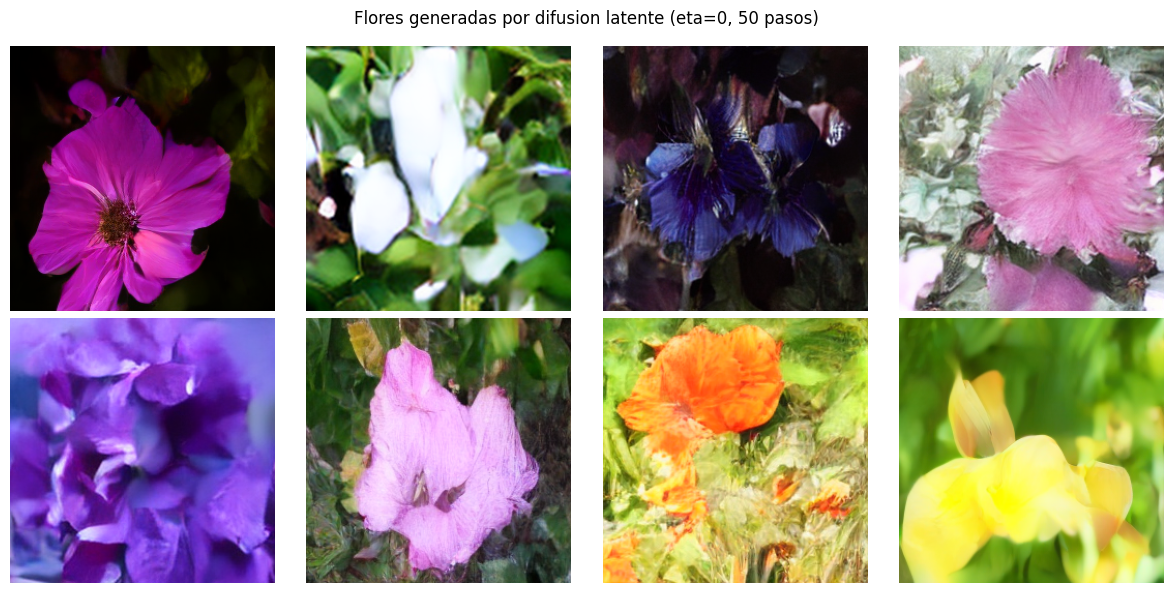

In [ ]:
import numpy as np


@torch.no_grad()
def eta_sample_latent(model, diffusion, n, steps, eta, cfg, device=DEVICE, seed=None):
    if seed is not None:
        torch.manual_seed(seed)
    model.eval()
    T = diffusion.T

    # instantes de tiempo, de mas ruido (T-1) a sin ruido (0)
    tiempos = np.linspace(0, T - 1, steps + 1).round().astype(int)[::-1]

    # estado inicial: ruido gaussiano puro en el latente
    x = torch.randn(n, cfg['latent_ch'], cfg['latent_size'], cfg['latent_size'], device=device)

    for i in range(steps):
        t_actual = int(tiempos[i])
        t_siguiente = int(tiempos[i + 1])
        ab_actual = diffusion.alpha_bars[t_actual]
        ab_siguiente = diffusion.alpha_bars[t_siguiente]

        # 1) la red predice el ruido del latente actual
        t_batch = torch.full((n,), t_actual, device=device, dtype=torch.long)
        ruido_predicho = model(x, t_batch)

        # 2) estimamos el latente limpio x0 (sin clamp: el latente no vive en [-1,1])
        x0_estimado = (x - torch.sqrt(1 - ab_actual) * ruido_predicho) / torch.sqrt(ab_actual)

        # 3) cuanto azar fresco inyectar (0 si eta=0)
        sigma = eta * torch.sqrt((1 - ab_siguiente) / (1 - ab_actual)) * torch.sqrt(1 - ab_actual / ab_siguiente)

        # 4) coeficiente del ruido predicho (la parte que no es azar nuevo)
        coef_ruido = torch.sqrt(torch.clamp(1 - ab_siguiente - sigma ** 2, min=0.0))

        # 5) azar fresco, salvo en el ultimo paso
        if i < steps - 1:
            z = torch.randn_like(x)
        else:
            z = torch.zeros_like(x)

        # 6) paso hacia atras: nuevo latente, un poco mas limpio
        x = torch.sqrt(ab_siguiente) * x0_estimado + coef_ruido * ruido_predicho + sigma * z

    return x


# generar 8 flores y decodificarlas
z = eta_sample_latent(latent_model, diffusion, n=8, steps=50, eta=0.0, cfg=CONFIG, seed=0)
imagenes = (decode(z).cpu() + 1) / 2

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(imagenes[i].permute(1, 2, 0).numpy().clip(0, 1))
    ax.axis('off')
plt.suptitle('Flores generadas por difusion latente (eta=0, 50 pasos)')
plt.tight_layout()
plt.savefig(os.path.join(CONFIG['work_dir'], 'muestras_latente.png'), dpi=150, bbox_inches='tight')
plt.show()